# Настроение треков: кластеризация и рекомендации

Прототип рекомендаций по настроению на готовых аудио-признаках Spotify (tempo, energy, valence, danceability, loudness), ~278 тыс. треков.
Сырое аудио не анализируется. Бэкенда нет: это исследовательский ноутбук.

## 1. Данные

In [16]:
import pandas as pd

In [17]:
import os

# полный датасет лежит локально и в репозиторий не входит; без него берём небольшой сэмпл
DATA = '278k_labelled_uri.csv' if os.path.exists('278k_labelled_uri.csv') else 'data/sample_5k.csv'
df = pd.read_csv(DATA)
print('Данные:', DATA, df.shape)
print(df.columns.tolist())       # все столбцы
print(df.iloc[:, -1].value_counts())  # распределение по классам эмоций

Данные: data/sample_5k.csv (5000, 15)
['Unnamed: 0.1', 'Unnamed: 0', 'duration (ms)', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'spec_rate', 'labels', 'uri']
uri
spotify:track:0NHPfnQMzg0GiwbC4SF2yR    1
spotify:track:22h3imNbWvskfto1OBLSaX    1
spotify:track:47IXLhp3c6mu7NqvpuhuLi    1
spotify:track:2hLxucFzyVxjS47MFyJ9tr    1
spotify:track:5YzzWlWfAVNvtduNDHKhHc    1
                                       ..
spotify:track:5KQFczIaGHJauFZXMh0GEx    1
spotify:track:0qa61a11y8VvXD55YqLMMc    1
spotify:track:3txD9phequal7R6apqVm57    1
spotify:track:3IwPKonJGuZ4kjH5pO2T3q    1
spotify:track:71JZqDcDt1AGip7Lsml41y    1
Name: count, Length: 5000, dtype: int64


In [18]:
print(df.columns.tolist())
print(df.shape)
print(df.head(3))

['Unnamed: 0.1', 'Unnamed: 0', 'duration (ms)', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'spec_rate', 'labels', 'uri']
(5000, 15)
   Unnamed: 0.1  Unnamed: 0  duration (ms)  danceability  energy  loudness  \
0        117141      117141       352800.0         0.810   0.624    -4.980   
1        201088      201088       180675.0         0.703   0.653    -6.226   
2        218334      218334       210240.0         0.703   0.866    -4.363   

   speechiness  acousticness  instrumentalness  liveness  valence    tempo  \
0       0.0367         0.595          0.000000     0.336    0.556  111.992   
1       0.0790         0.237          0.000000     0.199    0.414  140.044   
2       0.1870         0.292          0.000229     0.481    0.610  128.006   

      spec_rate  labels                                   uri  
0  1.040249e-07       1  spotify:track:22h3imNbWvskfto1OBLSaX  
1  4.372492e-07       1  spotify:tra

## 2. Подбор числа кластеров (silhouette)

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Берём только нужные признаки
features_mood = df[['tempo', 'energy', 'valence', 'danceability', 'loudness']]

# Нормализуем
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_mood)

# Проверяем силуэт для разных k
for k in range(3, 10):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels, sample_size=10000)
    print(f"k={k}, silhouette={score:.3f}")

k=3, silhouette=0.245
k=4, silhouette=0.231
k=5, silhouette=0.217
k=6, silhouette=0.219
k=7, silhouette=0.211
k=8, silhouette=0.203
k=9, silhouette=0.194


## 3. Кластеризация (k=5) и профили кластеров

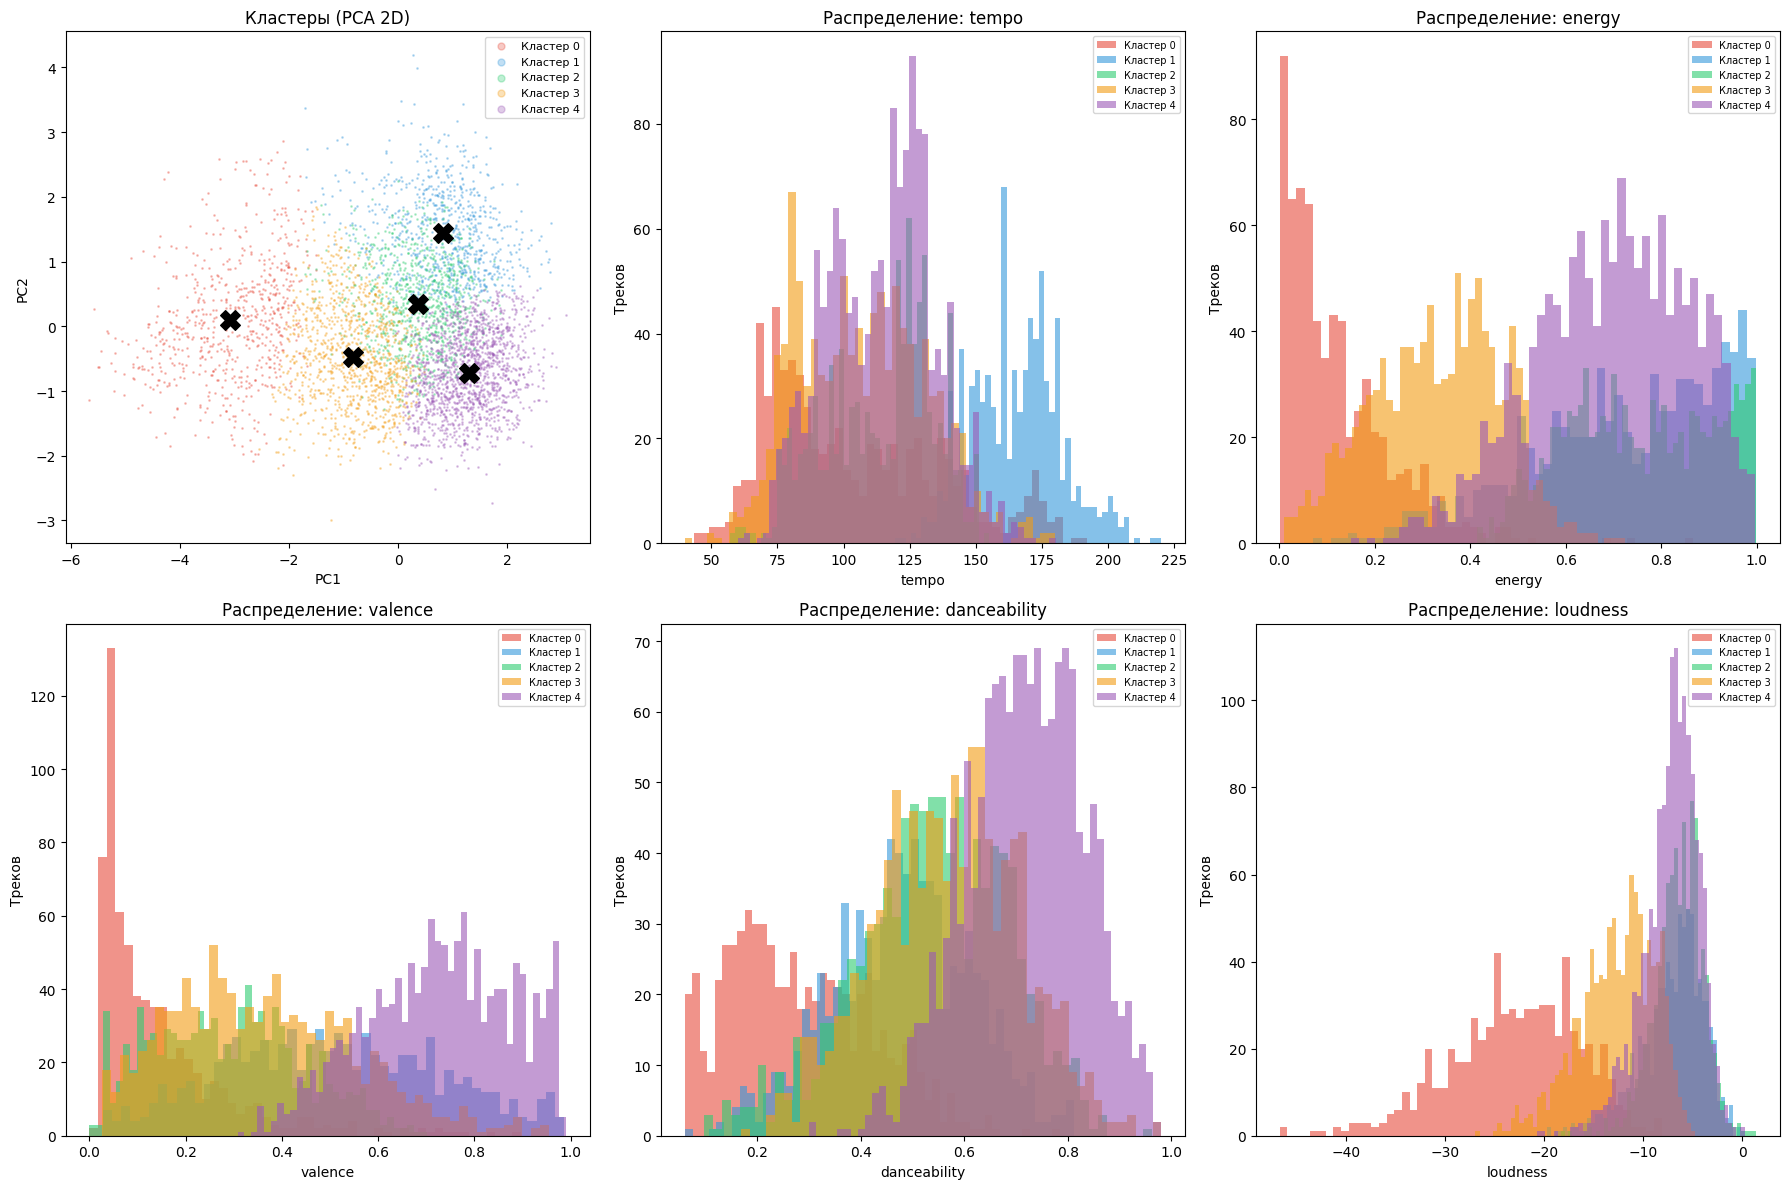


Средние значения по кластерам
           tempo  energy  valence  danceability  loudness
cluster                                                  
0        103.553   0.122    0.145         0.284   -22.944
1        164.921   0.723    0.504         0.477    -7.077
2        113.521   0.756    0.289         0.538    -6.385
3        106.775   0.332    0.361         0.567   -12.618
4        114.626   0.695    0.726         0.717    -7.146

Размер кластеров:
cluster
0     673
1     813
2     961
3    1061
4    1492
Name: count, dtype: int64


In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

features_mood = df[['tempo', 'energy', 'valence', 'danceability', 'loudness']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_mood)

# Кластеризуем с k=5
kmeans = KMeans(n_clusters=5, random_state=42)
labels = kmeans.fit_predict(X_scaled)

colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
feature_names = ['tempo', 'energy', 'valence', 'danceability', 'loudness']

fig = plt.figure(figsize=(18, 12))

# 1. Кластеры в 2D через PCA (только для визуализации)
ax1 = fig.add_subplot(2, 3, 1)
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
for i in range(5):
    mask = labels == i
    ax1.scatter(X_2d[mask, 0], X_2d[mask, 1],
                c=colors[i], label=f'Кластер {i}',
                alpha=0.3, s=1)
centers_2d = pca.transform(kmeans.cluster_centers_)
ax1.scatter(centers_2d[:, 0], centers_2d[:, 1],
            c='black', marker='X', s=200, zorder=5)
ax1.set_title('Кластеры (PCA 2D)')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend(markerscale=5, fontsize=8)

# 2-6. Распределение каждого признака по кластерам
for idx, feature in enumerate(feature_names):
    ax = fig.add_subplot(2, 3, idx + 2)
    for i in range(5):
        mask = labels == i
        ax.hist(features_mood[feature].values[mask],
                bins=50, alpha=0.6, color=colors[i],
                label=f'Кластер {i}')
    ax.set_title(f'Распределение: {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Треков')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig('mood_clusters.png', dpi=120)
plt.show()

# Средние значения признаков по кластерам
print("\nСредние значения по кластерам")
df_clusters = features_mood.copy()
df_clusters['cluster'] = labels
print(df_clusters.groupby('cluster').mean().round(3))
print("\nРазмер кластеров:")
print(df_clusters['cluster'].value_counts().sort_index())

In [21]:
score = silhouette_score(X_scaled, labels, sample_size=10000)
print(f"silhouette={score:.3f}")

silhouette=0.217


## 4. Классификатор кластеров (быстрый инференс)

Метки здесь получены из KMeans по тем же признакам, поэтому метрики ниже показывают, насколько точно лес воспроизводит кластеры, а не качество определения настроения.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import joblib

# 1. Добавляем псевдометки к датафрейму
cluster_to_mood = {
    0: 0,  # энергичная
    1: 1,  # радостная
    2: 2,  # грустная
    3: 3,  # спокойная
    4: 4   # тёмная
}

df_model = features_mood.copy()
df_model['mood'] = [cluster_to_mood[l] for l in labels]

# 2. Делим на train/test
X = df_model[['tempo', 'energy', 'valence', 'danceability', 'loudness']]
y = df_model['mood']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Обучаем классификатор
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)

# 4. Оцениваем качество
print(classification_report(y_test, clf.predict(X_test)))

# 5. Важность признаков
importances = pd.Series(clf.feature_importances_,
                        index=X.columns).sort_values(ascending=False)
print("\nВажность признаков")
print(importances.round(3))

# 6. Сохраняем модель и скейлер
joblib.dump(clf, 'mood_classifier.pkl')
joblib.dump(scaler, 'mood_scaler.pkl')
print("\nМодель сохранена: mood_classifier.pkl")

              precision    recall  f1-score   support

           0       0.96      0.94      0.95       138
           1       0.95      0.95      0.95       173
           2       0.95      0.93      0.94       185
           3       0.91      0.92      0.91       211
           4       0.97      0.97      0.97       293

    accuracy                           0.95      1000
   macro avg       0.95      0.94      0.94      1000
weighted avg       0.95      0.95      0.95      1000


Важность признаков
valence         0.258
tempo           0.216
energy          0.213
danceability    0.170
loudness        0.143
dtype: float64

Модель сохранена: mood_classifier.pkl


              precision    recall  f1-score   support

  энергичная      0.956     0.942     0.949       138
   радостная      0.948     0.954     0.951       173
    грустная      0.945     0.930     0.937       185
   спокойная      0.907     0.919     0.913       211
      тёмная      0.969     0.973     0.971       293

    accuracy                          0.946      1000
   macro avg      0.945     0.944     0.944      1000
weighted avg      0.946     0.946     0.946      1000

Macro F1: 0.944


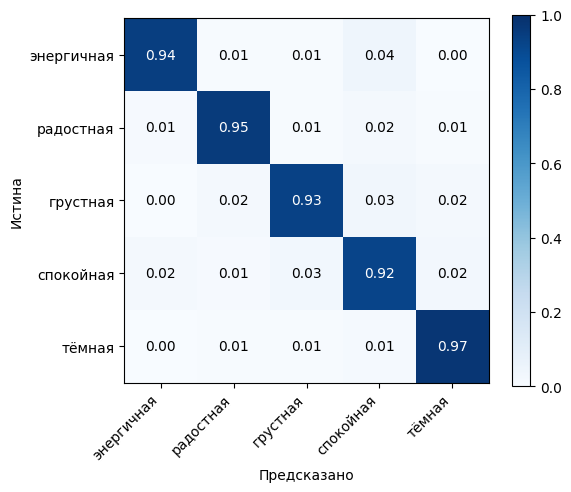

CV macro F1 по 5 фолдам: [0.953 0.974 0.958 0.952 0.951]
Среднее: 0.958 ± 0.008


In [23]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

mood_names = ['энергичная', 'радостная', 'грустная', 'спокойная', 'тёмная']

y_pred = clf.predict(X_test)

# отчёт по каждому классу: precision/recall/f1/support
print(classification_report(y_test, y_pred, target_names=mood_names, digits=3))
print('Macro F1:', round(f1_score(y_test, y_pred, average='macro'), 3))

# confusion matrix — какие настроения путает модель
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(mood_names, rotation=45, ha='right')
ax.set_yticklabels(mood_names)
ax.set_xlabel('Предсказано'); ax.set_ylabel('Истина')
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center',
                color='white' if cm_norm[i, j] > 0.5 else 'black')
fig.colorbar(im)
plt.tight_layout()
plt.show()

# кросс-валидация — насколько метрика стабильна от разбиения к разбиению
cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    X, y, cv=5, scoring='f1_macro'
)
print('CV macro F1 по 5 фолдам:', cv_scores.round(3))
print('Среднее:', round(cv_scores.mean(), 3), '±', round(cv_scores.std(), 3))

## 5. Примеры треков из каждого кластера

In [24]:
# Добавляем метки к исходному датафрейму
df['mood'] = labels

# Смотрим по 5 треков из каждого кластера
for mood_id in range(5):
    print(f"\nКластер {mood_id}")
    sample = df[df['mood'] == mood_id]['uri'].sample(5).values
    for uri in sample:
        # Превращаем uri в ссылку
        track_id = uri.split(':')[-1]
        print(f"https://open.spotify.com/track/{track_id}")


Кластер 0
https://open.spotify.com/track/0dRJyiEdzeHyX06nifP0jI
https://open.spotify.com/track/1KhDWwoN1bgejA3ouosRr2
https://open.spotify.com/track/1neW540exG7Nm22gWhiHDu
https://open.spotify.com/track/2ELGnSdAgGJ39GcymZPUdO
https://open.spotify.com/track/1iiNGLareyph69mzwYYBnn

Кластер 1
https://open.spotify.com/track/07NxDD1iKCHbAldceD7QLP
https://open.spotify.com/track/667syd1tZcEr9YLPemxSL6
https://open.spotify.com/track/58jecLK0epwMLr9cy5vFUy
https://open.spotify.com/track/7eyPDz0eM8wBHSC3PhEYep
https://open.spotify.com/track/2EXlXLfRmKXmDF3HDcPCPy

Кластер 2
https://open.spotify.com/track/6AZFTXEbrftYn5Ca0PaKru
https://open.spotify.com/track/6CFzhfVX4iJlDdLCR6kdgh
https://open.spotify.com/track/35pK1tKZTKiV5rBrWhJda1
https://open.spotify.com/track/5EDz9U8TS0spv8IH5sGHLw
https://open.spotify.com/track/72xDxwWk5h3XfGXcCWJASo

Кластер 3
https://open.spotify.com/track/3NEqlWNmH8KHJnHfpQ9wu1
https://open.spotify.com/track/4VvzZJHForqSUN7BRHcqFM
https://open.spotify.com/track/51NILp1

In [25]:
print(df['mood'].value_counts())
print(df['mood'].unique())

mood
4    1492
3    1061
2     961
1     813
0     673
Name: count, dtype: int64
[4 2 1 3 0]


## 6. Рекомендации по настроению

Схема: трек относится к кластеру (настроению), внутри кластера треки ранжируются по близости признаков
(евклидово расстояние в стандартизованном пространстве). Для нового трека кластер определяется через `kmeans.predict`.

Оценка: для 2000 случайных треков считаем долю рекомендаций с той же **реальной** эмоцией из датасета (precision@10)
и сравниваем с baseline.

In [26]:
import numpy as np
from IPython.display import Markdown, display
from sklearn.neighbors import NearestNeighbors

# строка i в df == строка i в X_scaled == элемент i в labels
labels = np.asarray(labels)
mood_names = ['энергичная', 'радостная', 'грустная', 'спокойная', 'тёмная']
cluster_members = {c: np.where(labels == c)[0] for c in range(5)}


def _top_n(idx, dist, n):
    n = min(n, len(idx))
    part = np.argpartition(dist, n - 1)[:n]
    return idx[part[np.argsort(dist[part])]]


def recommend_in_cluster(i, n=10):
    """n ближайших к треку i треков из того же кластера (сам трек исключён)."""
    members = cluster_members[labels[i]]
    members = members[members != i]
    dist = np.linalg.norm(X_scaled[members] - X_scaled[i], axis=1)
    return _top_n(members, dist, n)


# baseline-вариант: ближайшие по всей базе, без кластеров
nn_all = NearestNeighbors(algorithm='kd_tree').fit(X_scaled)


def recommend_global(i, n=10):
    idx = nn_all.kneighbors(X_scaled[[i]], n_neighbors=n + 1, return_distance=False)[0]
    return idx[idx != i][:n]


def recommend_new(tempo, energy, valence, danceability, loudness, n=5):
    """Рекомендации для трека, которого нет в датасете: по его признакам."""
    new = pd.DataFrame([[tempo, energy, valence, danceability, loudness]], columns=feature_names)
    z = scaler.transform(new)
    c = int(kmeans.predict(z)[0])
    members = cluster_members[c]
    dist = np.linalg.norm(X_scaled[members] - z[0], axis=1)
    return c, _top_n(members, dist, n)


def link(i):
    return 'https://open.spotify.com/track/' + df['uri'].iloc[i].split(':')[-1]


# пример для трека не из датасета
c, recs = recommend_new(tempo=120, energy=0.8, valence=0.7, danceability=0.75, loudness=-6)
print('Группа:', mood_names[c])
for j in recs:
    print(link(j))

Группа: тёмная
https://open.spotify.com/track/0ZOUc69GEvD2vKmZLIR5zm
https://open.spotify.com/track/1FPpmNizxiWVGfTiYD8OoP
https://open.spotify.com/track/2kojMQf4p5RlrzF9FRMjDi
https://open.spotify.com/track/11VRbqIoImi99kotcVUDKw
https://open.spotify.com/track/4ItCrsLmxUptz41S7OTZuS


## 7. Оценка: лучше ли рекомендации случайных?

In [27]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

label_col = 'labels'
y_true = df[label_col].to_numpy()
print('Колонка с реальными метками:', label_col)
print(df[label_col].value_counts(), '\n')

print('ARI:', round(adjusted_rand_score(y_true, labels), 3),
      '| NMI:', round(normalized_mutual_info_score(y_true, labels), 3))
display(pd.crosstab(df[label_col], labels, normalize='index').round(2)
        .rename_axis(index='реальная эмоция', columns='кластер'))

rng = np.random.default_rng(42)
N = 10
eval_idx = rng.choice(len(df), size=min(2000, len(df)), replace=False)


def precision_at_n(rec_fn):
    return float(np.mean([(y_true[rec_fn(i)] == y_true[i]).mean() for i in eval_idx]))


results = {
    'случайные из всей базы': precision_at_n(lambda i: rng.choice(len(df), N, replace=False)),
    'случайные из того же кластера': precision_at_n(lambda i: rng.choice(cluster_members[labels[i]], N, replace=False)),
    'ближайшие по всей базе (без кластеров)': precision_at_n(lambda i: recommend_global(i, N)),
    'ближайшие внутри кластера (наш метод)': precision_at_n(lambda i: recommend_in_cluster(i, N)),
}
display(pd.DataFrame({f'precision@{N}': results}).round(3))

Колонка с реальными метками: labels
labels
1    1924
0    1525
2     817
3     734
Name: count, dtype: int64 

ARI: 0.255 | NMI: 0.299


кластер,0,1,2,3,4
реальная эмоция,,,,,
0,0.13,0.12,0.15,0.49,0.12
1,0.00,0.14,0.22,0.06,0.59
2,0.00,0.42,0.38,0.00,0.20
3,0.65,0.04,0.01,0.29,0.01


,precision@10
случайные из всей базы,0.284
случайные из того же кластера,0.487
ближайшие по всей базе (без кластеров),0.659
ближайшие внутри кластера (наш метод),0.656


## 8. Примеры рекомендаций

Случайные исходные треки (не отобранные вручную). Ссылки ведут на Spotify.

In [28]:
def show_examples(k=5, n=5, seed=7):
    r = np.random.default_rng(seed)
    lines = ['| Исходный трек | Группа | Рекомендации |', '|---|---|---|']
    for i in r.choice(len(df), k, replace=False):
        recs = ' · '.join(f'[{m + 1}]({link(j)})' for m, j in enumerate(recommend_in_cluster(i, n)))
        lines.append(f'| [трек]({link(i)}) | {mood_names[labels[i]]} | {recs} |')
    md = '\n'.join(lines)
    with open('examples.md', 'w', encoding='utf-8') as f:
        f.write(md)
    display(Markdown(md))


show_examples()

| Исходный трек | Группа | Рекомендации |
|---|---|---|
| [трек](https://open.spotify.com/track/6l2FkcCf2vYXjoczVqBKEg) | спокойная | [1](https://open.spotify.com/track/09BQblETwD3QF1HLZk3QzD) · [2](https://open.spotify.com/track/4QqQ6S3pDocGvUzF4fSVuS) · [3](https://open.spotify.com/track/2RJnNdu4pb3MypbBroHU0T) · [4](https://open.spotify.com/track/6u5PNKpwoJrMEnCY0hTkAi) · [5](https://open.spotify.com/track/6x1Ji00Z81c7vbC3nYwcr1) |
| [трек](https://open.spotify.com/track/5R4xZGCHERUBnxbpuSLpwF) | энергичная | [1](https://open.spotify.com/track/1GhIGedE1Jf8IkmmBHoYH7) · [2](https://open.spotify.com/track/6pu1TDfkHvwpCoxzEGrZx2) · [3](https://open.spotify.com/track/5MuaATdeBH9T7JSJorteXi) · [4](https://open.spotify.com/track/6C0xrpCLSiAIm242vKE7HA) · [5](https://open.spotify.com/track/0UFBuB1arDtnsmHNPFAd7N) |
| [трек](https://open.spotify.com/track/6qOF2WazgLpZ6YRb9TOPxq) | грустная | [1](https://open.spotify.com/track/6n2GPvMJtFZ4ckoc9EWHMx) · [2](https://open.spotify.com/track/39Zb3y5PrBJuVRwRw6zNIl) · [3](https://open.spotify.com/track/0E3KzwCg0gRXUPVNAnWBXr) · [4](https://open.spotify.com/track/0Y5lftJhV50jLIy3xc1alV) · [5](https://open.spotify.com/track/3yowm56ant5XMV1X6o71DK) |
| [трек](https://open.spotify.com/track/6M80LrXmyQB2BybPFUGJnt) | тёмная | [1](https://open.spotify.com/track/7CwhEjnn3O8kuRl4iqjauj) · [2](https://open.spotify.com/track/3hD0zbTa7vquHzCavbmMf3) · [3](https://open.spotify.com/track/3B0aVYHRUPaGUqRjuSNPak) · [4](https://open.spotify.com/track/4NPCztm07oskLbIAqbsxoC) · [5](https://open.spotify.com/track/6qDLGV4JSQ2vwjdBNjxoHX) |
| [трек](https://open.spotify.com/track/0R0o8uOkDz40XsR6uwThfQ) | спокойная | [1](https://open.spotify.com/track/7AQim7LbvFVZJE3O8TYgf2) · [2](https://open.spotify.com/track/34L7Ur4vOGpfTPOeljDfYL) · [3](https://open.spotify.com/track/6PQmbLYv07IprWdrNeJFjT) · [4](https://open.spotify.com/track/3YYJspIMzSibIvk9IzvEwA) · [5](https://open.spotify.com/track/000u1dTg7y1XCDXi80hbBX) |